#Data Management ET4015-Exam Report, June 2022

Group Members:


*   Davide Giardini, 975026@stud.unive.it, 975026
*   Irene Buso, 881030@stud.unive.it, 881030



# 0)Import libraries

In [30]:
#we import all libraries
import os # needed to interact with the operating system (e.g. save/load a database)
import numpy as np # numerical library (linear algebra)
import pandas as pd # table manipulation. Based on numpy
from matplotlib import pyplot as plt # plots
import seaborn as sns # based on matplotlib. Very powerful plot library
import sqlite3 # needed to write SQL code in our notebooks and convert the results into Python tables.

try:
    os.remove("database.db")
except OSError:
    pass

# the following stuff simplifies the interaction with SQL
conn = sqlite3.connect("database.db")
cur = conn.cursor()

def run_sql(sql_command): # executes a SQL code
  cur.execute(sql_command)
  conn.commit()
  if cur.description != None:
    col_names = [i[0] for i in cur.description]
    result = pd.DataFrame(cur.fetchall(), columns = col_names)
    result
    return result

def dataframe_to_table(df,table_name): # converts a dataframe into a SQL table in our database.
  df.to_sql(table_name, conn, if_exists='replace', index = False)
  conn.commit()

#1)Introduction

This project deals with covid-19 cases from the beginning of the pandemic in different countries and the effects that several vaccines had on world population

##1.1 Datasets
We used this datasets and the related csv files included in the project folder


###With the following command we converted CSV datasets into dataframes

In [31]:

COVIDstates_df = pd.read_csv("COVID_stati_tutti.csv")
Geography_df = pd.read_csv("Geography_data.csv")
Manifacturer_df = pd.read_csv("manifacturer.csv")
Pollution_df = pd.read_csv("pollution.csv")
Populationarea_df = pd.read_csv("Population_area.csv")
VACCINATIONSstates_df = pd.read_csv("vaccini.csv")




In [32]:

dataframe_to_table(COVIDstates_df,"COVIDstates_tmp")
dataframe_to_table(Geography_df,"Geography_tmp")
dataframe_to_table(Manifacturer_df,"Manifacturer_tmp")
dataframe_to_table(Pollution_df,"Pollution_tmp")
dataframe_to_table(Populationarea_df,"Populationarea_tmp")
dataframe_to_table(VACCINATIONSstates_df,"VACCINATIONSstates_tmp")

# 2)Database specification and Logic Design


We want to represent the Covid-19 situation in 15 countries before and after vaccination. Each country is identify by an ID, name, population, land area, latitude/longitude. Countries recorded the pandemic evolution using covid records. Different cases are subdivided in confirmed, deaths and recovered. Each country can have more than 1 covid record due to different date. Since the beginning of the vaccination campaign, countries also had vaccination records, identified by the date and the number of people vaccinated. Vaccines can be provided by several manifactures with different names

Countries(_ID_, name, population, latitude/longitude, land area)

Vaccination_record(_data_, people vaccinated country ID: fk to Countries(ID))

manifactures(_name_)

Covid_record(_data_, recovered, deaths, confirmed) Country_ID: fk to Countries(ID)

Administered(total_number_vaccinations, vaccinedate,vState, vID:fk to Countries(ID), vaccine_manifacturer: fk to manifactures)

# 3)Physical design
We create sql tables following our ERscheme

In [33]:
run_sql ('''
CREATE TABLE Countries (
  ID char (2) primary key,
  cName varchar (255),
  cPopulation int,
  cArea float,
  cLatitude float,
  cLongitude float
  );


''');

In [34]:
run_sql ('''
create table Covidrecord (
  rdate date,
  rconfirmed int,
  rrecovered int,
  rdeaths int,
  rcountryID char (2) references Countries(ID)
  );
  ''');


In [35]:
run_sql ('''
create table Vaccinationsrecord(
  vDate date,
  vpeople_vaccinated int,
  vcountryID char (2) references Countries(ID)
  );
  ''');

In [36]:
run_sql ('''

create table Vaccine_manifacturers (
  mName varchar (255) primary KEY
  );
  ''');


In [37]:
run_sql('''
create table Vaccinecountries(
  Vstate varchar (255),
  vID char (2) references Countries(ID),
  vaccinedate "date",
  vaccine_manifacturer varchar(255) references Vaccine_manifacturers(mName),
  total_number_vaccinations int
  );

 ''');

# 4)We insert the data into the tables we created


Countries

In [38]:
run_sql ('''
insert into Countries

select countryid, name, population, land_area, latitude, longitude
FROM Geography_tmp, Populationarea_tmp
WHERE Populationarea_tmp.country=Geography_tmp.name

''');

Covidrecord

In [39]:
run_sql ('''

insert into Covidrecord

SELECT cdatelist, confirmed, recovered, deaths, countryid
from COVIDstates_tmp, Geography_tmp
where COVIDstates_tmp.country=Geography_tmp.name
;

''');

Vaccinationsrecord

In [40]:
run_sql ('''
insert into Vaccinationsrecord

SELECT vdatelist, people_vaccinated, id
from VACCINATIONSstates_tmp, Countries
where VACCINATIONSstates_tmp.country=cname
;


''');

Vaccine_Manifacturers

In [41]:
run_sql('''

 insert into Vaccine_manifacturers values
    ("Pfizer/BioNtech"),
    ("Moderna") ,
    ("Oxford/Astrazeneca"),
    ("Johnson&Johnson") ,
    ("Sputnik_V") ,
    ("Sinovac") ,
    ("Sinopharm/Beijing"),
    ("CanSino"),
    ("Novavax") ,
    ("Covaxin");

''');

Vaccinecountries

In [42]:
run_sql ('''

insert into Vaccinecountries

SELECT cname, ID,date, vaccine, total_vaccinations
from Manifacturer_tmp, Countries
where Countries.cname=Manifacturer_tmp.location
;

''');

# Query **1**

In [43]:
run_sql ('''
create table Query1 (
  Date "date",
  ID char (2),
  name varchar (255),
  vaccinated int,
  population int,
  VAX float
  );
  ''');

In [44]:
run_sql ('''
 insert into Query1

 select vDate, vcountryID, cName, vpeople_vaccinated, cPopulation,CAST(vpeople_vaccinated AS float) / CAST(cpopulation AS float) AS 'VAX'
 from Countries, Vaccinationsrecord
 where Vaccinationsrecord.vcountryID=Countries.ID



''');

In [45]:
run_sql('''
select *
from Query1
group by name
order by VAX desc
''')

,Date,ID,name,vaccinated,population,VAX
0,2021-05-21,VG,British Virgin Islands,11255,30266,0.371869
1,2021-05-25,CK,Cook Islands,4363,17567,0.248363
2,2021-04-27,TV,Tuvalu,2400,11817,0.203097
3,2021-03-29,AW,Aruba,15600,106845,0.146006
4,2021-01-27,GL,Greenland,2584,56787,0.045503
...,...,...,...,...,...,...
186,2021-02-04,AI,Anguilla,0,15026,0.000000
187,2021-03-01,AO,Angola,0,33032075,0.000000
188,2021-01-29,DZ,Algeria,0,43984569,0.000000
189,2021-01-10,AL,Albania,0,2877239,0.000000


The first query shows all countries sorted by decreasing VAX value (vaccinated/population)

# QUERY 2

In [46]:
run_sql ('''
select ID, cName,rconfirmed, cArea, MIN (rapport)
from (
select ID, cName,rconfirmed, cArea, rconfirmed/cArea AS "rapport"
from Countries, Covidrecord
where rcountryID=ID
group by id
);
''')

,ID,cName,rconfirmed,cArea,MIN (rapport)
0,AD,Andorra,0,470.0,0.0


The output of the second query shows that Micronesia has the smallest number of case confirmed per square kilometer

# QUERY 3

In [47]:
run_sql ('''

select rdate, cname, clatitude, clongitude, rdeaths, cpopulation, MAX (relative_deaths)
from (
select rdate, cname, clatitude, clongitude, rdeaths, cpopulation, CAST (rdeaths as float)/cpopulation as "relative_deaths"
from Countries, Covidrecord
where rcountryID=ID and clatitude > 0 and rdate BETWEEN '2020-10-01' and '2020-10-31'
group by cname
);

''')

,rdate,cname,clatitude,clongitude,rdeaths,cpopulation,MAX (relative_deaths)
0,2020-10-01,San Marino,43.94236,12.457777,42,33944,0.001237


Largest number of relative cases in the northern emisphere

In [48]:
run_sql ('''

select rdate, cname, clatitude, clongitude, rdeaths, cpopulation, MAX (relative_deaths)
from (
select rdate, cname, clatitude, clongitude, rdeaths, cpopulation, CAST (rdeaths as float)/cpopulation as "relative_deaths"
from Countries, Covidrecord
where rcountryID=ID and clatitude < 0 and rdate BETWEEN '2020-10-01' and '2020-10-31'
group by cname
);

''')

,rdate,cname,clatitude,clongitude,rdeaths,cpopulation,MAX (relative_deaths)
0,2020-10-01,Peru,-9.189967,-75.015152,82294,33050211,0.00249


Largest number of relative cases in the southern emisphere

# Query per plots


We create a query and call it plot1query (in order to use it with Seaborn) for England

In [49]:
plot1query=run_sql ('''

select rdate, rconfirmed,rdeaths,rcountryID,vpeople_vaccinated
from (
select rdate, rconfirmed,rdeaths,rcountryID,vpeople_vaccinated
from Covidrecord, Vaccinationsrecord
where rcountryid=vcountryid and vdate=rdate)
where rcountryid= 'GB'
AND vpeople_vaccinated > 0


''')
plot1query


,rdate,rconfirmed,rdeaths,rcountryID,vpeople_vaccinated
0,2021-01-10,3081319,81567,GB,2286572
1,2021-01-11,3127617,82096,GB,2431648
2,2021-01-12,3173273,83340,GB,2639309
3,2021-01-13,3220936,84909,GB,2918252
4,2021-01-14,3269737,86162,GB,3234946
...,...,...,...,...,...
456,2022-04-12,21846115,171004,GB,52959181
457,2022-04-13,21883579,171662,GB,52978585
458,2022-04-14,21916961,172014,GB,53001426
459,2022-04-15,21916961,172014,GB,53012870


We create a query and call it plot2query (in order to use it with Seaborn) for Israel

In [50]:
plot2query=run_sql ('''

select rdate, rconfirmed,rdeaths,rcountryID,vpeople_vaccinated
from (
select rdate, rconfirmed,rdeaths,rcountryID,vpeople_vaccinated
from Covidrecord, Vaccinationsrecord
where rcountryid=vcountryid and vdate=rdate)
where rcountryid= 'IL'


''')
plot2query


,rdate,rconfirmed,rdeaths,rcountryID,vpeople_vaccinated
0,2020-12-19,372886,3074,IL,68
1,2020-12-20,374760,3099,IL,7459
2,2020-12-21,378259,3111,IL,32379
3,2020-12-22,382487,3136,IL,77038
4,2020-12-23,385022,3150,IL,139946
...,...,...,...,...,...
479,2022-04-12,4013193,10601,IL,6707013
480,2022-04-13,4016912,10601,IL,6707130
481,2022-04-14,4022685,10612,IL,6707212
482,2022-04-15,4025943,10612,IL,6707221


## PLOTS
**ENGLAND**

<Axes: xlabel='rdate', ylabel='rdeaths'>

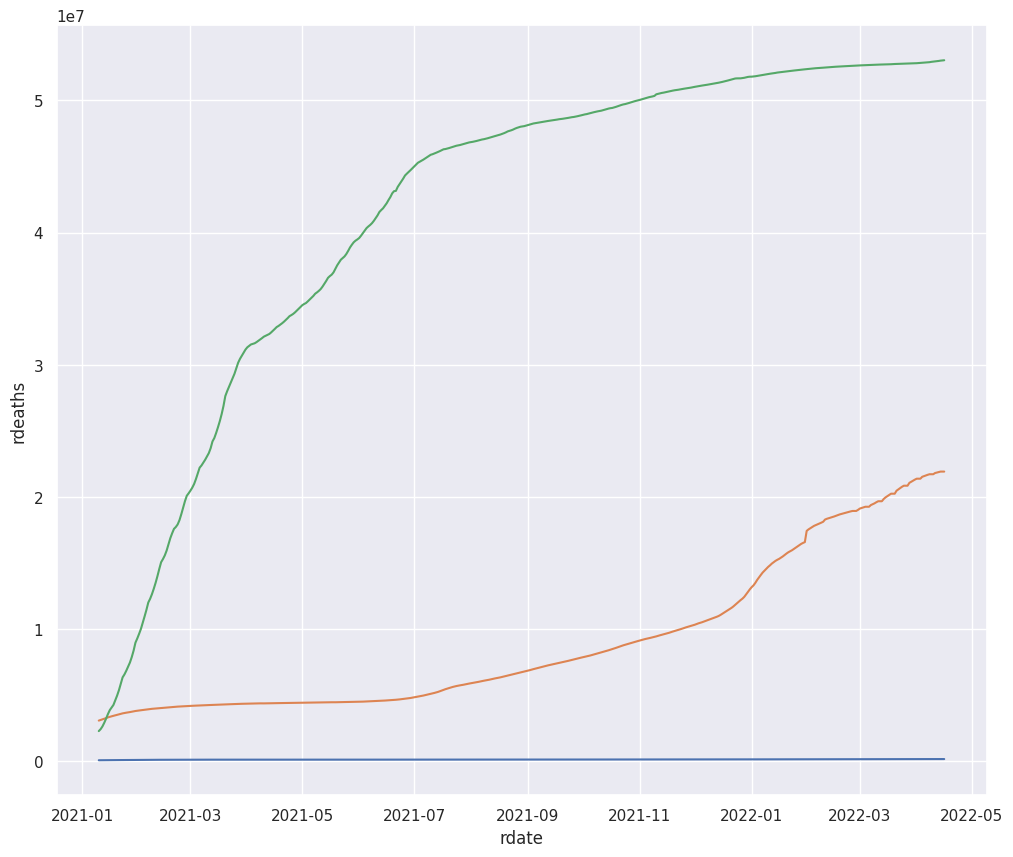

In [51]:
plot1query['rdate'] = pd.to_datetime(plot1query['rdate'])
sns.set(rc={'figure.figsize':(12,10)})
sns.lineplot(x='rdate', y='rdeaths',  data = plot1query)

sns.lineplot(x='rdate', y='rconfirmed',  data = plot1query)

sns.lineplot(x='rdate', y='vpeople_vaccinated',  data = plot1query)



One plot to compare confirmed cases, deaths and vaccinations

<Axes: xlabel='rdate', ylabel='rdeaths'>

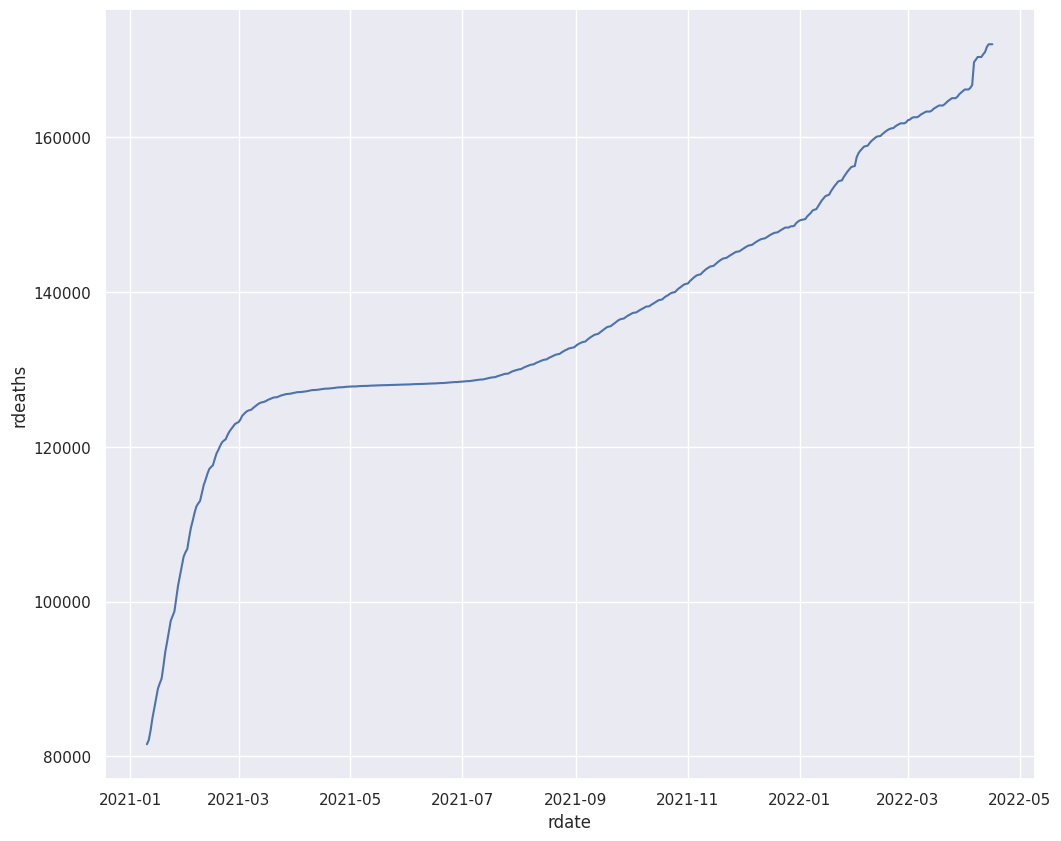

In [52]:
sns.set(rc={'figure.figsize':(12,10)})
sns.lineplot(x='rdate', y='rdeaths',  data = plot1query)

Only deaths in order to show better data as they are relatively smaller than other two

## PLOT **ISRAELE**

<Axes: xlabel='rdate', ylabel='rdeaths'>

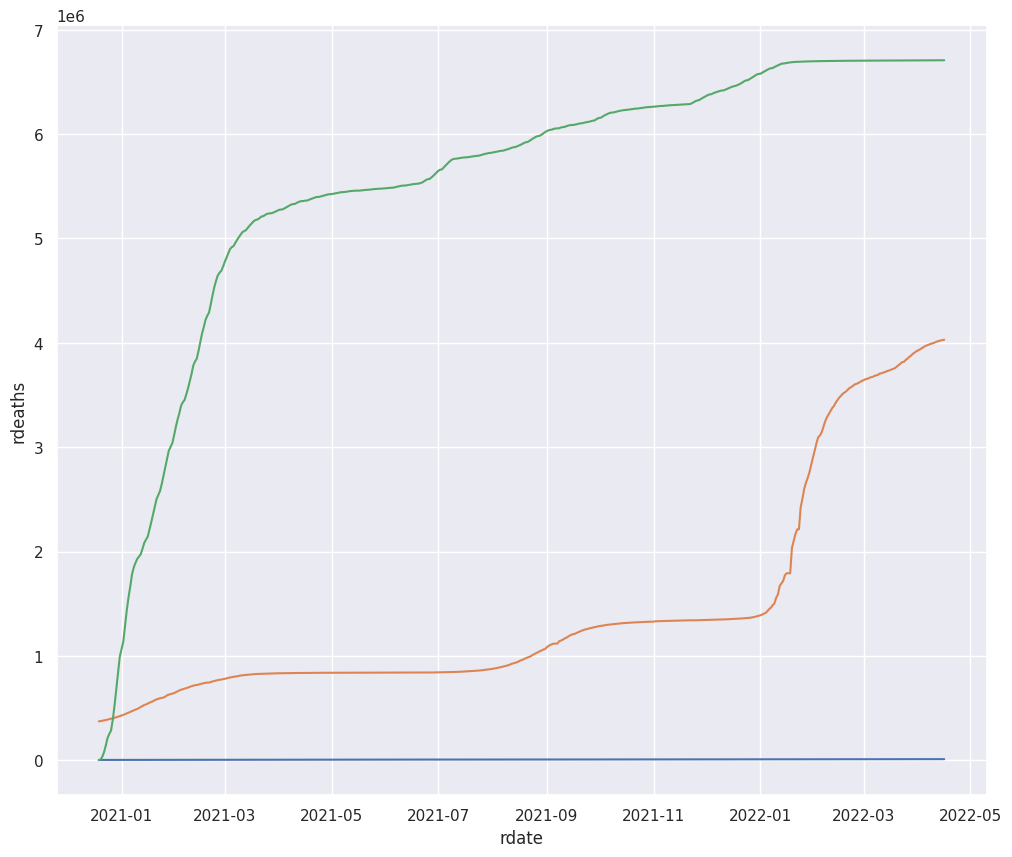

In [53]:
plot2query['rdate'] = pd.to_datetime(plot2query['rdate'])
sns.set(rc={'figure.figsize':(12,10)})
sns.lineplot(x='rdate', y='rdeaths',  data = plot2query)
sns.lineplot(x='rdate', y='rconfirmed',  data = plot2query)
sns.lineplot(x='rdate', y='vpeople_vaccinated',  data = plot2query)

One plot to compare confirmed cases, deaths and vaccinations

<Axes: xlabel='rdate', ylabel='rdeaths'>

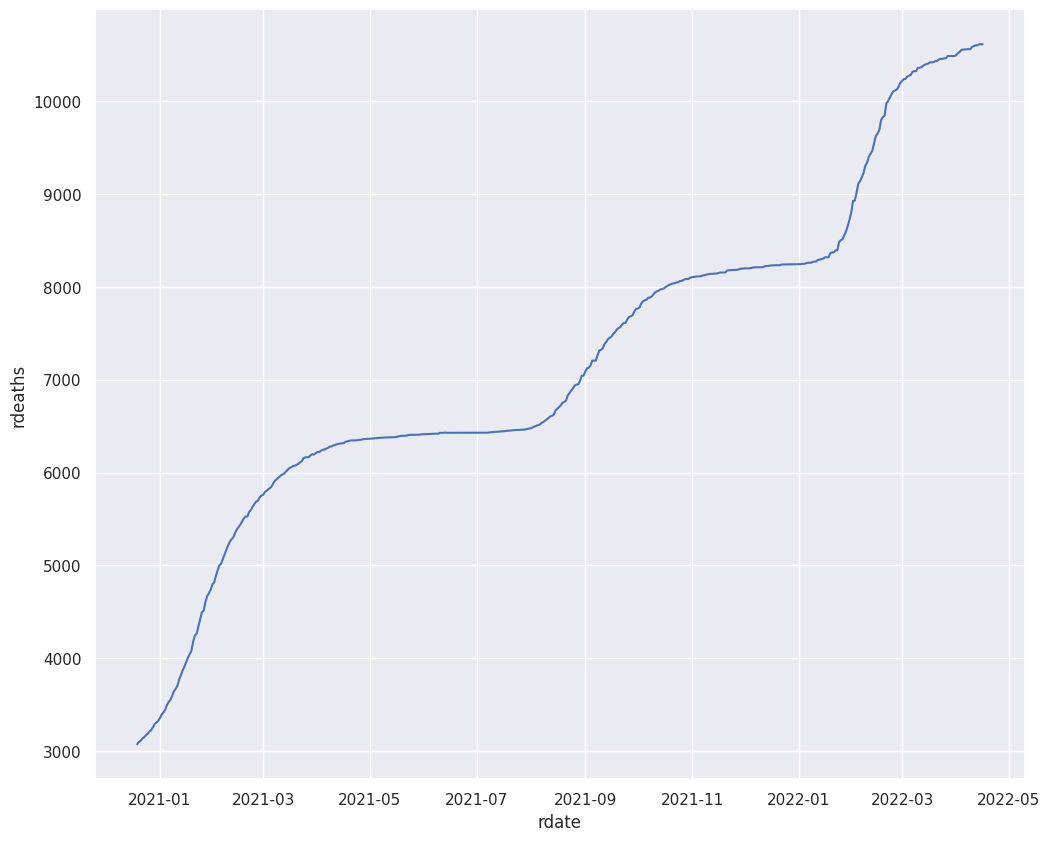

In [54]:
sns.set(rc={'figure.figsize':(12,10)})
sns.lineplot(x='rdate', y='rdeaths',  data = plot2query)

Only deaths in order to show better data as they are relatively smaller than other two

## PLOT 2

In [55]:
plot3query=run_sql('''
WITH increments AS (
    SELECT vaccinedate, vaccine_manifacturer,
           total_number_vaccinations -
           COALESCE(LAG(total_number_vaccinations) OVER (
               PARTITION BY vID, vaccine_manifacturer
               ORDER BY vaccinedate
           ), 0) AS incremento
    FROM vaccinecountries
),
daily AS (
    SELECT vaccinedate, vaccine_manifacturer,
           SUM(incremento) AS incremento
    FROM increments
    GROUP BY vaccinedate, vaccine_manifacturer
)
SELECT vaccinedate, vaccine_manifacturer,
       SUM(incremento) OVER (
           PARTITION BY vaccine_manifacturer
           ORDER BY vaccinedate
       ) AS total
FROM daily
ORDER BY vaccinedate
''')
plot3query

,vaccinedate,vaccine_manifacturer,total
0,2020-12-04,Moderna,1
1,2020-12-07,Pfizer/BioNTech,1
2,2020-12-09,Pfizer/BioNTech,2
3,2020-12-15,Pfizer/BioNTech,3
4,2020-12-16,Pfizer/BioNTech,4
...,...,...,...
4702,2022-06-04,Sinopharm/Beijing,71601517
4703,2022-06-04,Sinovac,61621228
4704,2022-06-04,Sputnik V,22388732
4705,2022-06-05,Johnson&Johnson,51048039


Cumulative number of vaccinations adminstered in the world clustered by manifacturers

<Axes: xlabel='vaccinedate', ylabel='total'>

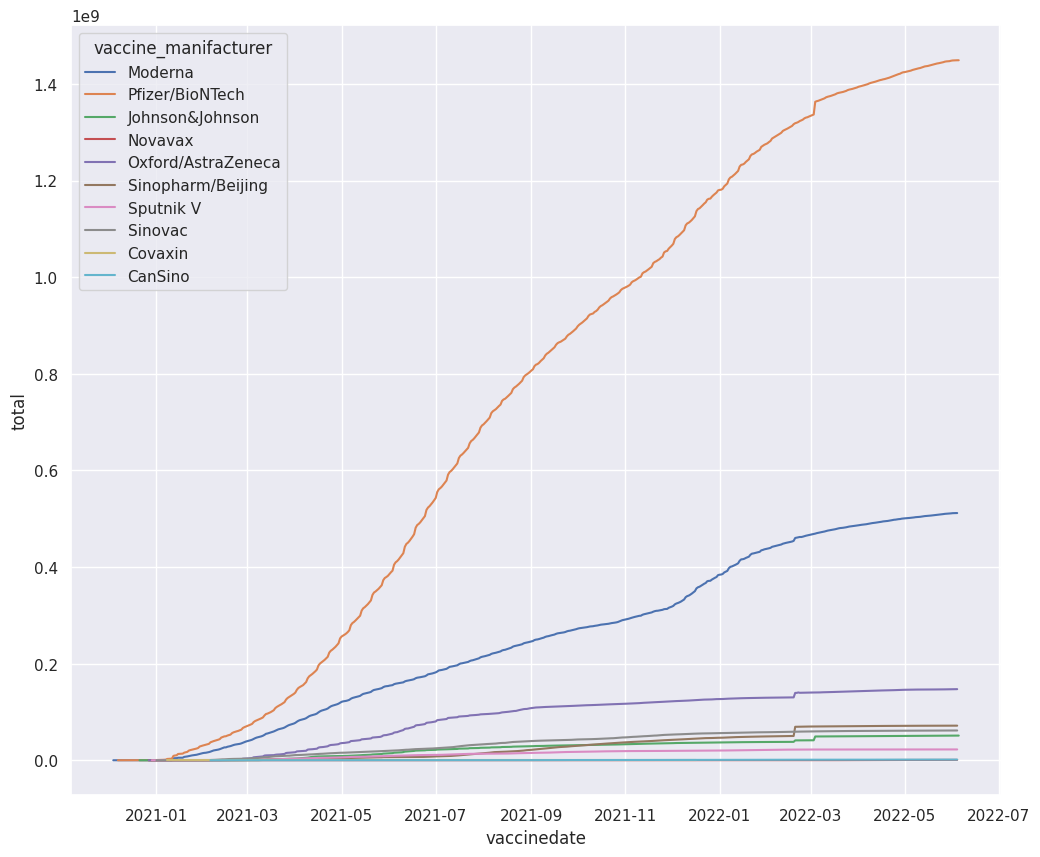

In [56]:
plot3query['vaccinedate'] = pd.to_datetime(plot3query['vaccinedate'])
sns.lineplot(x='vaccinedate', y='total', hue='vaccine_manifacturer',  data = plot3query)

PLOT **3**

In [57]:
plot4query= run_sql ('''

select  vDate, vcountryID, cname, vpeople_vaccinated, cpopulation, CAST(vpeople_vaccinated AS float) / CAST(cpopulation AS float) AS 'Ratio'
from Countries, Vaccinationsrecord
where vcountryid=ID and vdate> '2021-09-01'and vcountryid IN ('IT', 'FR', 'BR', 'DE', 'CH', 'CA', 'AU', 'LK') AND vpeople_vaccinated > 0
order by vDate
''')
plot4query

,vDate,vcountryID,cName,vpeople_vaccinated,cPopulation,Ratio
0,2021-09-02,AU,Australia,12640002,25550683,0.494703
1,2021-09-02,BR,Brazil,137897705,212821986,0.647949
2,2021-09-02,CA,Canada,28081896,37799407,0.742919
3,2021-09-02,FR,France,49346670,65298930,0.755704
4,2021-09-02,DE,Germany,55546952,83830972,0.662607
...,...,...,...,...,...,...
2060,2022-06-03,IT,Italy,50787545,60446035,0.840213
2061,2022-06-04,BR,Brazil,184062381,212821986,0.864865
2062,2022-06-04,IT,Italy,50788054,60446035,0.840221
2063,2022-06-05,BR,Brazil,184077691,212821986,0.864937


<Axes: xlabel='vDate', ylabel='Ratio'>

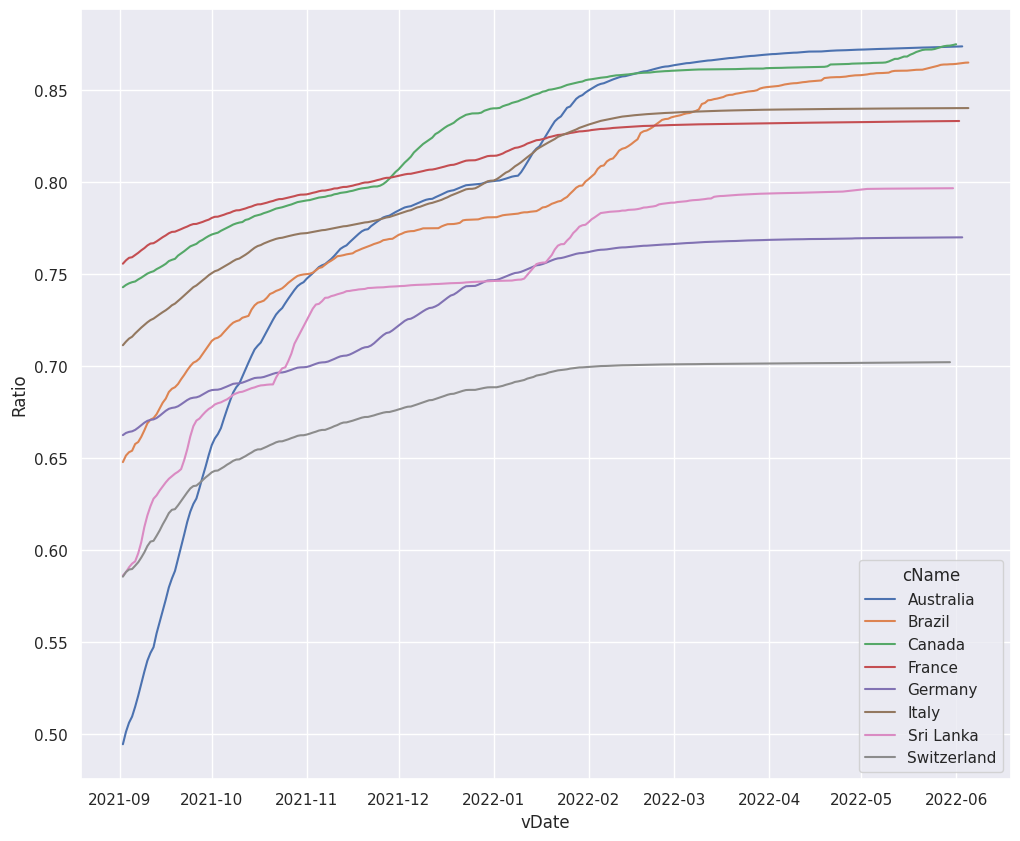

In [58]:
plot4query['vDate'] = pd.to_datetime(plot4query['vDate'])
sns.lineplot(x='vDate', y='Ratio', hue='cName',  data = plot4query)

Vaccinations rates as a function of time from September 2021

#Discussion
We discovered that there was a sharp rise of covid cases and, in the highest peak of the pandemic, consequently deaths and, with the first campaigns of vaccinations, numbers slowed down as the vaccination campaign went on.